# Modul 7: Seltsame Attraktoren & Fraktale Dimension

---

## Die Geometrie des Chaos

In dissipativen Systemen sind chaotische Trajektorien aperiodisch und beschränkt. Wohin konvergieren sie?

Zu einem **seltsamen Attraktor** - einer Menge mit:
- **Fraktaler Struktur**: Selbstähnlichkeit auf allen Skalen
- **Nicht-ganzzahliger Dimension**: "Mehr" als eine Fläche, "weniger" als ein Volumen
- **Null Volumen**: Hat Lebesgue-Maß Null
- **Unendlicher Länge**: Enthält unendlich viel Struktur

Die fraktale Dimension quantifiziert diese "Zwischen-Dimensionalität".

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.spatial.distance import pdist
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams.update({
    'figure.figsize': (12, 10),
    'figure.dpi': 100,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'lines.linewidth': 0.5,
})

%matplotlib inline

---

## 7.1 Was ist ein Attraktor?

**Definition:** Ein **Attraktor** $A$ ist eine Menge im Phasenraum mit:
1. **Invarianz**: Trajektorien, die auf $A$ starten, bleiben auf $A$
2. **Attraktion**: Trajektorien aus einer Umgebung konvergieren zu $A$
3. **Minimalität**: $A$ hat keine echte Teilmenge mit diesen Eigenschaften

### Typen von Attraktoren

| Typ | Dimension | Beispiel |
|-----|-----------|----------|
| Fixpunkt | 0 | Gedämpfter Oszillator |
| Grenzzyklus | 1 | Van-der-Pol |
| Torus | 2 | Quasiperiodische Bewegung |
| **Seltsamer Attraktor** | Fraktal (z.B. 2.06) | Lorenz |

Der **seltsame Attraktor** hat fraktale (nicht-ganzzahlige) Dimension!

---

## 7.2 Fraktale Dimension: Die Idee

### Das Problem der klassischen Dimension

Intuitiv:
- Eine Linie hat Dimension 1
- Eine Fläche hat Dimension 2
- Ein Volumen hat Dimension 3

Aber was ist mit einer Kurve, die so kompliziert ist, dass sie "fast" eine Fläche ausfüllt?

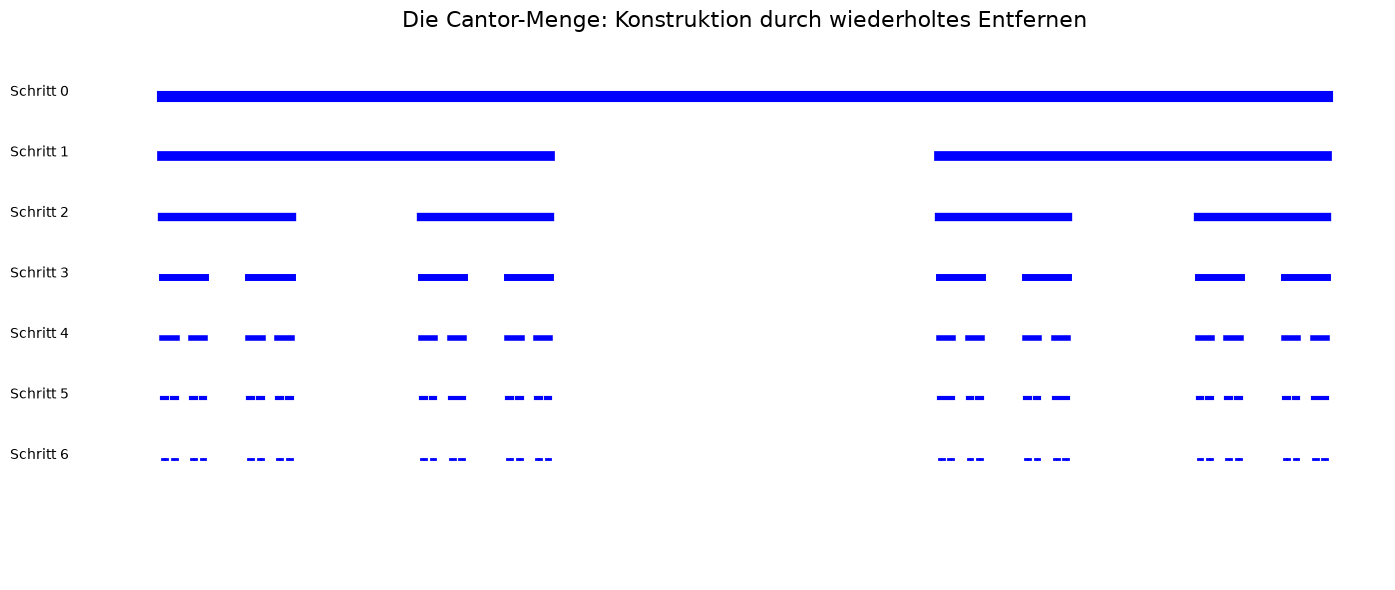

In [2]:
# Die Cantor-Menge: Prototyp eines Fraktals

def draw_cantor(ax, x_start, x_end, y, depth, max_depth):
    """Zeichnet die Cantor-Menge rekursiv."""
    if depth > max_depth:
        return
    
    # Zeichne aktuelles Intervall
    ax.plot([x_start, x_end], [y, y], 'b-', linewidth=max(1, 8 - depth))
    
    # Rekursion: Entferne mittleres Drittel
    length = (x_end - x_start) / 3
    draw_cantor(ax, x_start, x_start + length, y - 0.5, depth + 1, max_depth)
    draw_cantor(ax, x_end - length, x_end, y - 0.5, depth + 1, max_depth)

fig, ax = plt.subplots(figsize=(14, 6))
draw_cantor(ax, 0, 1, 0, 0, 6)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-4, 0.5)
ax.set_title('Die Cantor-Menge: Konstruktion durch wiederholtes Entfernen', fontsize=16)
ax.set_xlabel('x')
ax.axis('off')

# Beschriftungen
labels = ['Schritt 0', 'Schritt 1', 'Schritt 2', 'Schritt 3', 'Schritt 4', 'Schritt 5', 'Schritt 6']
for i, label in enumerate(labels):
    ax.text(-0.08, -0.5*i, label, fontsize=10, ha='right')

plt.tight_layout()
plt.show()

### Die Cantor-Menge: Eigenschaften

**Konstruktion:**
1. Starte mit [0, 1]
2. Entferne das mittlere Drittel (1/3, 2/3)
3. Wiederhole für jedes verbleibende Intervall
4. Grenzwert: Die Cantor-Menge $C$

**Eigenschaften von $C$:**
- Hat **überabzählbar viele Punkte** (gleich viele wie [0,1]!)
- Hat **Lebesgue-Maß Null** ("Länge" = 0)
- Ist **nirgends dicht** (enthält kein Intervall)
- Ist **perfekt** (jeder Punkt ist Häufungspunkt)
- Hat **fraktale Dimension** $D = \frac{\ln 2}{\ln 3} \approx 0.631$

Mehr als ein Punkt (D=0), weniger als eine Linie (D=1)!

---

## 7.3 Box-Counting Dimension

Die praktischste Definition der fraktalen Dimension.

**Algorithmus:**
1. Bedecke die Menge mit Würfeln/Quadraten der Seitenlänge $\epsilon$
2. Zähle, wie viele Boxen $N(\epsilon)$ nötig sind
3. Die Dimension ist:

$$D = \lim_{\epsilon \to 0} \frac{\ln N(\epsilon)}{\ln(1/\epsilon)}$$

In [3]:
def box_counting_dimension(points, epsilon_range=(0.01, 0.5), num_scales=20):
    """
    Schätzt die Box-Counting Dimension einer Punktmenge.
    """
    # Normalisiere auf [0,1]^d
    points = np.array(points)
    min_vals = points.min(axis=0)
    max_vals = points.max(axis=0)
    scale = max_vals - min_vals
    scale[scale == 0] = 1
    points_norm = (points - min_vals) / scale
    
    epsilons = np.logspace(np.log10(epsilon_range[0]), 
                           np.log10(epsilon_range[1]), num_scales)
    counts = []
    
    for eps in epsilons:
        # Diskretisiere Punkte zu Gitter
        grid_indices = np.floor(points_norm / eps).astype(int)
        # Zähle einzigartige Boxen
        unique_boxes = len(set(map(tuple, grid_indices)))
        counts.append(unique_boxes)
    
    counts = np.array(counts)
    
    # Lineare Regression im log-log Plot
    log_eps = np.log(1 / epsilons)
    log_N = np.log(counts)
    coeffs = np.polyfit(log_eps, log_N, 1)
    dimension = coeffs[0]
    
    return dimension, epsilons, counts

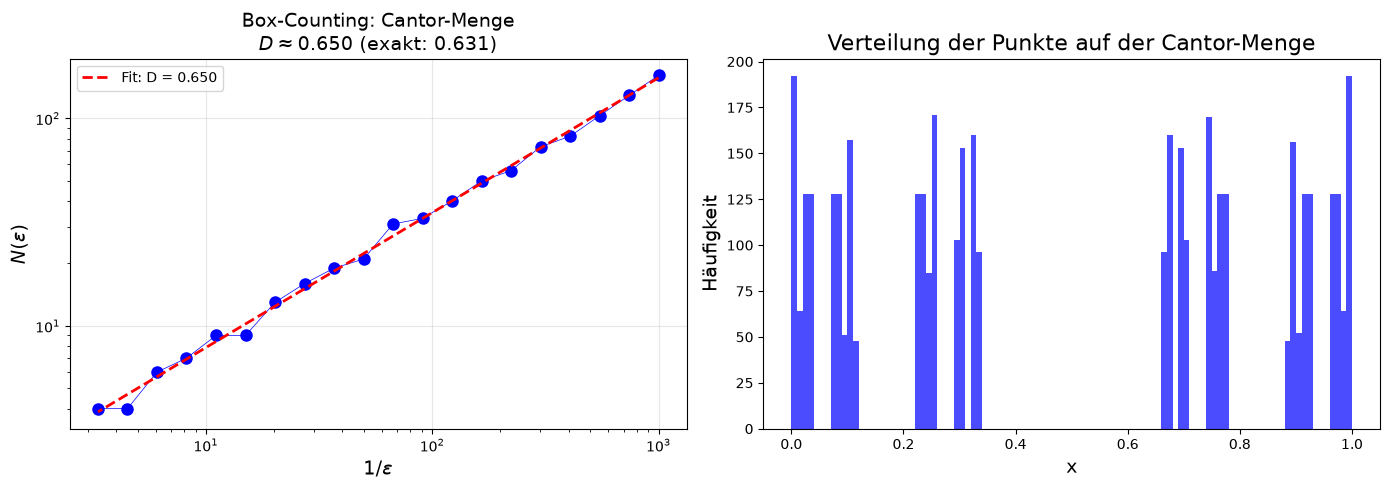

Geschätzte Dimension: D = 0.6498
Exakte Dimension: D = ln(2)/ln(3) = 0.6309


In [4]:
# Demonstration: Cantor-Menge

def generate_cantor_points(depth=12):
    """Erzeugt Punkte auf der Cantor-Menge."""
    points = [(0, 1)]
    for _ in range(depth):
        new_points = []
        for (a, b) in points:
            length = (b - a) / 3
            new_points.append((a, a + length))
            new_points.append((b - length, b))
        points = new_points
    
    # Mittelpunkte der Intervalle als Punkte
    return np.array([(a + b) / 2 for (a, b) in points]).reshape(-1, 1)

cantor_points = generate_cantor_points(12)
dim, eps, counts = box_counting_dimension(cantor_points, epsilon_range=(0.001, 0.3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-Log Plot
ax = axes[0]
ax.loglog(1/eps, counts, 'bo-', markersize=8)
ax.set_xlabel(r'$1/\epsilon$', fontsize=14)
ax.set_ylabel(r'$N(\epsilon)$', fontsize=14)
ax.set_title(f'Box-Counting: Cantor-Menge\n$D \\approx {dim:.3f}$ (exakt: {np.log(2)/np.log(3):.3f})', fontsize=14)
ax.grid(True, alpha=0.3)

# Fit-Linie
log_eps = np.log(1/eps)
fit_line = np.exp(dim * log_eps + np.polyfit(log_eps, np.log(counts), 1)[1])
ax.loglog(1/eps, fit_line, 'r--', linewidth=2, label=f'Fit: D = {dim:.3f}')
ax.legend()

# Histogramm der Punkte
ax = axes[1]
ax.hist(cantor_points.flatten(), bins=100, color='blue', alpha=0.7)
ax.set_xlabel('x')
ax.set_ylabel('Häufigkeit')
ax.set_title('Verteilung der Punkte auf der Cantor-Menge')

plt.tight_layout()
plt.show()

print(f"Geschätzte Dimension: D = {dim:.4f}")
print(f"Exakte Dimension: D = ln(2)/ln(3) = {np.log(2)/np.log(3):.4f}")

### Interpretation

Bei jeder Skala verdreifachen: Die Cantor-Menge besteht aus **2 Kopien** von sich selbst, jede um Faktor **3** verkleinert.

$$D = \frac{\ln(\text{Anzahl Kopien})}{\ln(\text{Skalierungsfaktor})} = \frac{\ln 2}{\ln 3} \approx 0.631$$

Das ist die **Selbstähnlichkeitsdimension** - bei exakt selbstähnlichen Fraktalen identisch zur Box-Counting Dimension.

---

## 7.4 Die Dimension des Lorenz-Attraktors

In [5]:
# Lorenz-Attraktor generieren

def lorenz(state, t, sigma=10, rho=28, beta=8/3):
    x, y, z = state
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

t = np.linspace(0, 200, 50000)  # Lange Zeit für viele Punkte
initial = [1, 1, 1]
sol = odeint(lorenz, initial, t)

# Transient überspringen
lorenz_points = sol[5000:]

print(f"Anzahl Punkte auf dem Attraktor: {len(lorenz_points)}")

Anzahl Punkte auf dem Attraktor: 45000


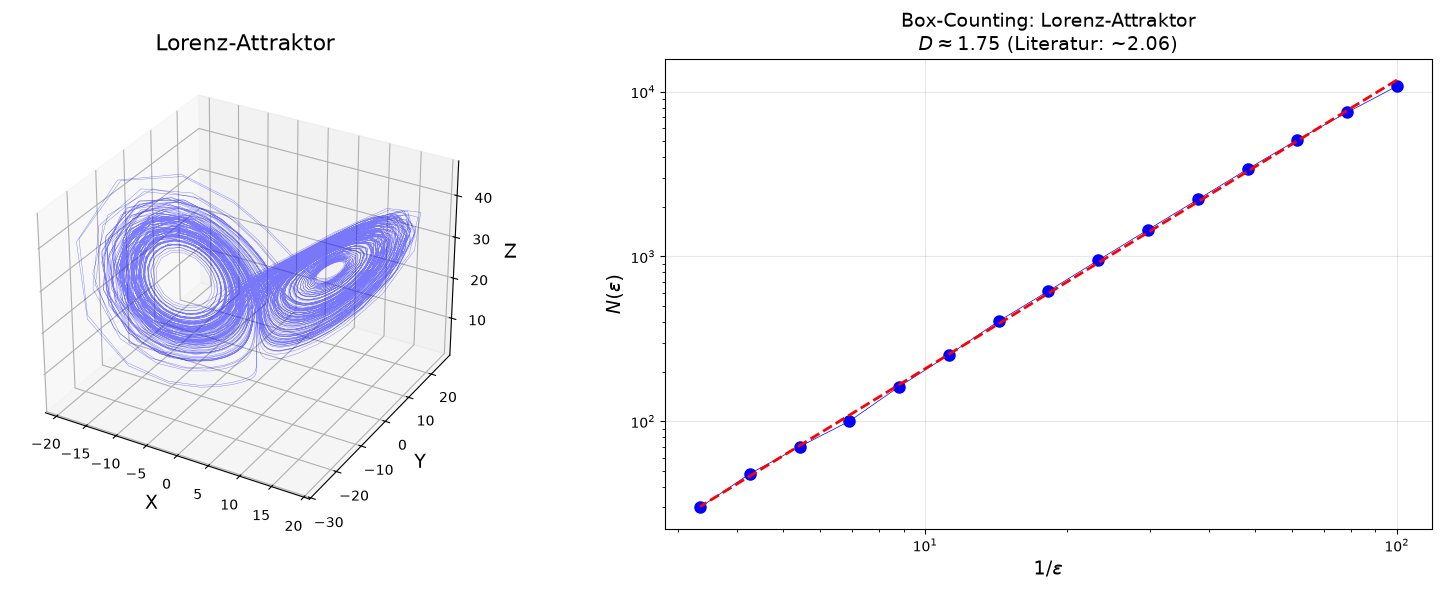

Geschätzte Dimension: D ≈ 1.75
Literaturwert: D ≈ 2.06


In [6]:
# Box-Counting Dimension des Lorenz-Attraktors

dim_lorenz, eps_lorenz, counts_lorenz = box_counting_dimension(
    lorenz_points, epsilon_range=(0.01, 0.3), num_scales=15
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 3D-Plot des Attraktors
axes[0].remove()
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot(lorenz_points[::10, 0], lorenz_points[::10, 1], lorenz_points[::10, 2],
       'b-', alpha=0.5, linewidth=0.3)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Lorenz-Attraktor')

# Box-Counting
ax = axes[1]
ax.loglog(1/eps_lorenz, counts_lorenz, 'bo-', markersize=8)

log_eps = np.log(1/eps_lorenz)
fit_line = np.exp(dim_lorenz * log_eps + np.polyfit(log_eps, np.log(counts_lorenz), 1)[1])
ax.loglog(1/eps_lorenz, fit_line, 'r--', linewidth=2)

ax.set_xlabel(r'$1/\epsilon$', fontsize=14)
ax.set_ylabel(r'$N(\epsilon)$', fontsize=14)
ax.set_title(f'Box-Counting: Lorenz-Attraktor\n$D \\approx {dim_lorenz:.2f}$ (Literatur: ~2.06)', fontsize=14)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Geschätzte Dimension: D ≈ {dim_lorenz:.2f}")
print(f"Literaturwert: D ≈ 2.06")

### Warum liegt die Schätzung unter 2.06?

Das ist kein Rechenfehler, sondern die bekannte Schwäche von Box-Counting: Ein endliches Trajektorienstück erreicht die selten besuchten Boxen nicht, und $N(\epsilon)$ fällt bei kleinem $\epsilon$ zu niedrig aus. Die Schätzung konvergiert dadurch sehr langsam - selbst mit 2 Millionen Punkten liegt die Steigung noch bei etwa 1.9.

Robuster ist die **Korrelationsdimension** (Grassberger & Procaccia, 1983). Sie misst den Anteil $C(r)$ aller Punktpaare, deren Abstand kleiner als $r$ ist:

$$C(r) \sim r^{D_2}$$

Selten besuchte Regionen fallen dabei kaum ins Gewicht, deshalb genügen wenige tausend Punkte.

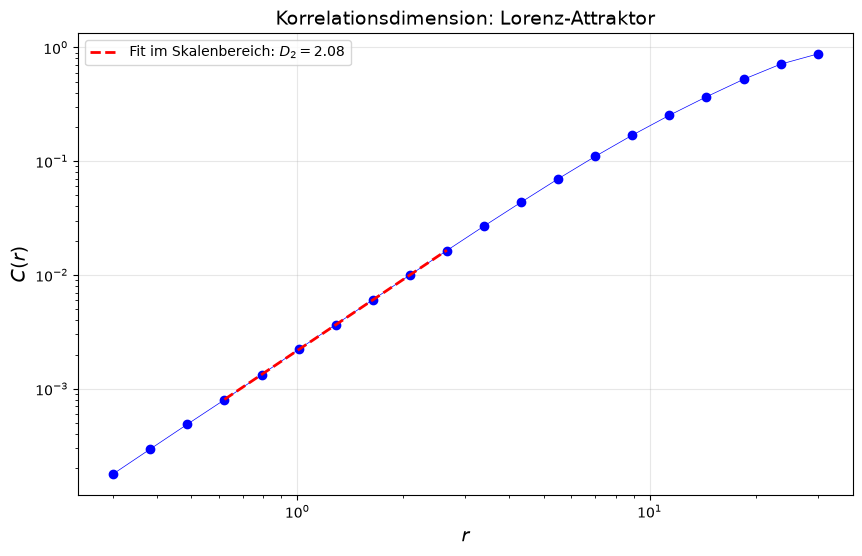

Korrelationsdimension: D₂ ≈ 2.08
Literaturwert: D₂ ≈ 2.05


In [7]:
# Korrelationsdimension des Lorenz-Attraktors (Grassberger-Procaccia)

rng = np.random.default_rng(42)
t_long = np.linspace(0, 1000, 50000)
sol_long = odeint(lorenz, initial, t_long)[1000:]
sample = sol_long[rng.choice(len(sol_long), 5000, replace=False)]

distances = pdist(sample)
r = np.logspace(np.log10(0.3), np.log10(30), 20)
C = np.array([(distances < ri).mean() for ri in r])

# Fit nur im Skalenbereich: Bei großem r stößt man an die Ausdehnung des Attraktors
scaling = (r >= 0.5) & (r <= 3)
dim_corr, intercept = np.polyfit(np.log(r[scaling]), np.log(C[scaling]), 1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(r, C, 'bo-', markersize=6)
ax.loglog(r[scaling], np.exp(intercept) * r[scaling]**dim_corr, 'r--', linewidth=2,
          label=f'Fit im Skalenbereich: $D_2 = {dim_corr:.2f}$')
ax.set_xlabel(r'$r$', fontsize=14)
ax.set_ylabel(r'$C(r)$', fontsize=14)
ax.set_title('Korrelationsdimension: Lorenz-Attraktor', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

print(f"Korrelationsdimension: D₂ ≈ {dim_corr:.2f}")
print(f"Literaturwert: D₂ ≈ 2.05")


### Die Dimension ~2.06: Was bedeutet das?

Der Lorenz-Attraktor ist:
- **Mehr als eine Fläche** (D > 2)
- **Weniger als ein Volumen** (D < 3)

Er ist eine **unendlich oft gefaltete Fläche** - dünn wie ein Blatt Papier, aber unendlich oft geknickt, sodass es "mehr" ist als eine einfache Fläche.

Die zusätzlichen 0.06 kommen vom Falten!

---

## 7.5 Der Hénon-Attraktor: 2D Chaos

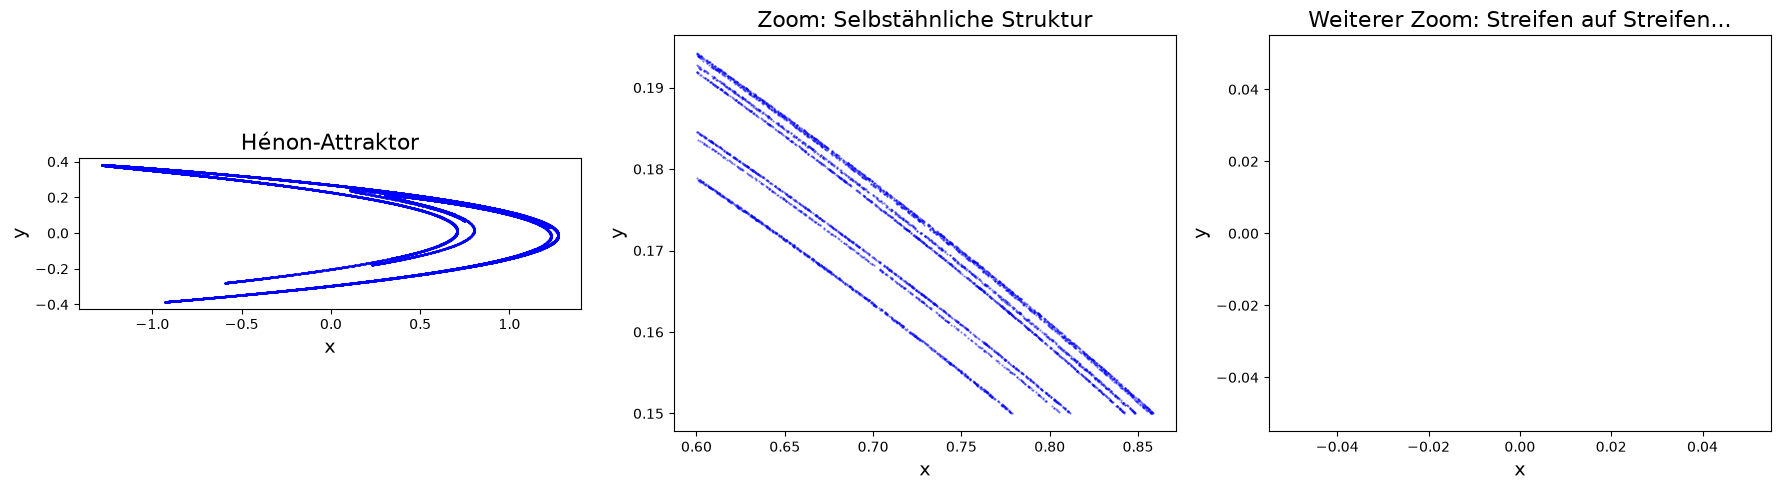

In [8]:
# Die Hénon-Abbildung: Das einfachste 2D chaotische System
# x_{n+1} = 1 - a*x_n^2 + y_n
# y_{n+1} = b*x_n

def henon_attractor(a=1.4, b=0.3, n_points=100000, transient=1000):
    """Erzeugt den Hénon-Attraktor."""
    x, y = 0, 0
    
    # Transient
    for _ in range(transient):
        x, y = 1 - a * x**2 + y, b * x
    
    # Attraktor
    points = []
    for _ in range(n_points):
        x, y = 1 - a * x**2 + y, b * x
        points.append([x, y])
    
    return np.array(points)

henon_points = henon_attractor()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Vollständiger Attraktor
ax = axes[0]
ax.scatter(henon_points[:, 0], henon_points[:, 1], s=0.1, c='blue', alpha=0.3)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Hénon-Attraktor')
ax.set_aspect('equal')

# Zoom 1
ax = axes[1]
mask = (henon_points[:, 0] > 0.6) & (henon_points[:, 0] < 1.0) & \
       (henon_points[:, 1] > 0.15) & (henon_points[:, 1] < 0.35)
ax.scatter(henon_points[mask, 0], henon_points[mask, 1], s=0.3, c='blue', alpha=0.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Zoom: Selbstähnliche Struktur')

# Zoom 2
ax = axes[2]
mask2 = (henon_points[:, 0] > 0.75) & (henon_points[:, 0] < 0.85) & \
        (henon_points[:, 1] > 0.2) & (henon_points[:, 1] < 0.26)
ax.scatter(henon_points[mask2, 0], henon_points[mask2, 1], s=1, c='blue', alpha=0.7)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Weiterer Zoom: Streifen auf Streifen...')

plt.tight_layout()
plt.show()

### Selbstähnlichkeit im Hénon-Attraktor

**Beobachtung:** Bei jedem Zoom-Level sieht man die gleiche Struktur:
- Parallele Streifen
- Die Streifen bestehen selbst aus parallelen Streifen
- Unendlich oft!

Dies ist das Resultat von **Stretching + Folding**:
- Die Hénon-Abbildung streckt in einer Richtung
- Und kontrahiert in der anderen
- Das Falten erzeugt die geschichtete Struktur

**Dimension:** $D \approx 1.26$ - mehr als eine Linie, weniger als eine Fläche

In [9]:
# Dimension des Hénon-Attraktors

dim_henon, eps_henon, counts_henon = box_counting_dimension(
    henon_points, epsilon_range=(0.002, 0.2), num_scales=15
)

print(f"Hénon-Attraktor Dimension: D ≈ {dim_henon:.2f}")
print(f"Literaturwert: D ≈ 1.26")

Hénon-Attraktor Dimension: D ≈ 1.26
Literaturwert: D ≈ 1.26


---

## 7.6 Der Zusammenhang: Lyapunov-Exponenten und Dimension

### Die Kaplan-Yorke Dimension

Es gibt einen tiefen Zusammenhang zwischen Lyapunov-Exponenten und fraktaler Dimension:

$$D_{KY} = j + \frac{\sum_{i=1}^{j} \lambda_i}{|\lambda_{j+1}|}$$

wobei $j$ der größte Index ist, für den $\sum_{i=1}^{j} \lambda_i \geq 0$.

**Für Lorenz:**
- $\lambda_1 \approx 0.91$ (Expansion)
- $\lambda_2 = 0$ (entlang Fluss)
- $\lambda_3 \approx -14.6$ (Kontraktion)

$$D_{KY} = 2 + \frac{0.91 + 0}{14.6} \approx 2.06$$

**Das passt zur oben gemessenen Korrelationsdimension $D_2$ (Literaturwert: $\approx 2.05$).** Box-Counting blieb darunter - das liegt an der Methode, nicht am Attraktor. (Streng genommen sind $D_{KY}$, $D_2$ und die Box-Dimension verschiedene Größen; beim Lorenz-Attraktor liegen sie dicht beieinander.)

### Interpretation

Die Information über die Anfangsbedingung wird:
- **Expandiert** in Richtung des positiven Lyapunov-Exponenten
- **Kontrahiert** in Richtung der negativen Exponenten

Die fraktale Dimension misst, wie viel "Raum" die Trajektorie effektiv einnimmt, gegeben diese Mischung aus Expansion und Kontraktion.

---

## 7.7 Weitere chaotische Systeme

Der Rössler-Attraktor ist ein weiterer seltsamer Attraktor. Das Doppelpendel dagegen ist ohne Reibung **konservativ**: Es zeigt Chaos, hat aber keinen Attraktor, weil das Phasenraumvolumen erhalten bleibt.

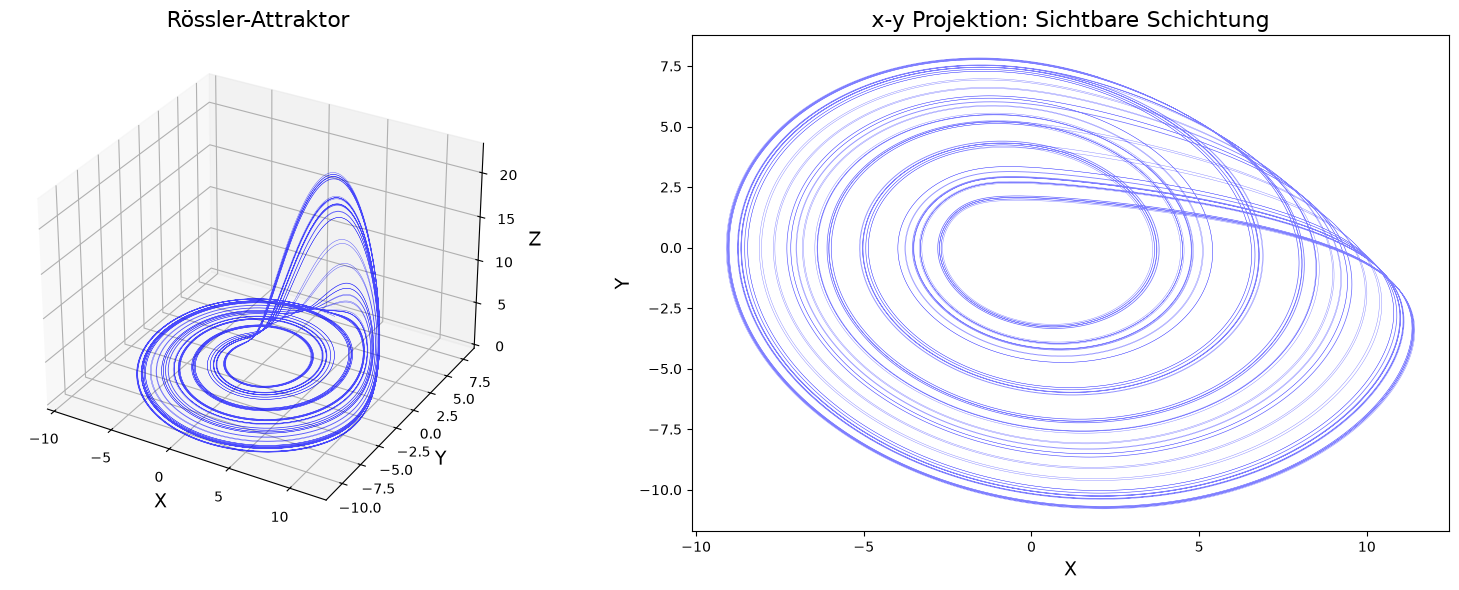

In [10]:
# Der Rössler-Attraktor: "Sauberer" als Lorenz

def rossler(state, t, a=0.2, b=0.2, c=5.7):
    x, y, z = state
    return [-y - z, x + a*y, b + z*(x - c)]

t = np.linspace(0, 500, 50000)
sol_rossler = odeint(rossler, [0.1, 0.1, 0.1], t)

fig = plt.figure(figsize=(16, 6))

# 3D
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot(sol_rossler[5000:, 0], sol_rossler[5000:, 1], sol_rossler[5000:, 2],
       'b-', alpha=0.7, linewidth=0.3)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Rössler-Attraktor')

# x-y Projektion
ax = fig.add_subplot(1, 2, 2)
ax.plot(sol_rossler[5000:, 0], sol_rossler[5000:, 1], 'b-', alpha=0.5, linewidth=0.3)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('x-y Projektion: Sichtbare Schichtung')

plt.tight_layout()
plt.show()

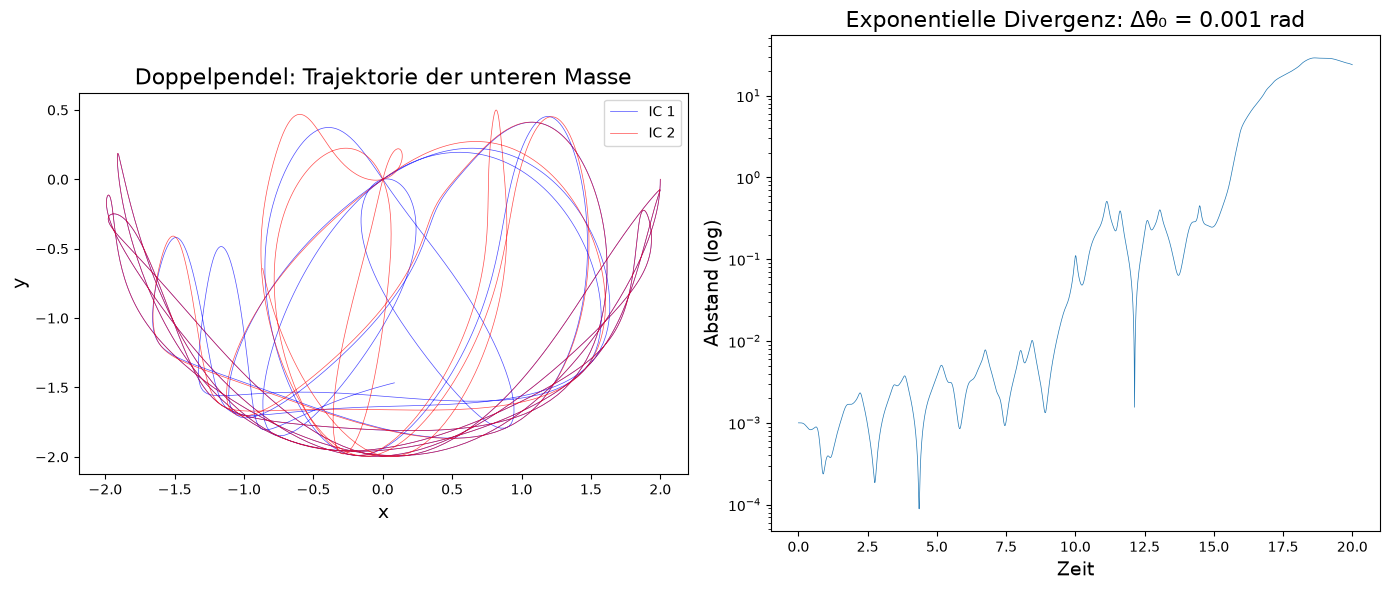

In [11]:
# Das Doppelpendel: Chaos in der Mechanik (konservativ, also ohne Attraktor)

def double_pendulum(state, t, L1=1, L2=1, m1=1, m2=1, g=9.81):
    """
    Doppelpendel-Gleichungen.
    state = [θ1, ω1, θ2, ω2]
    """
    th1, w1, th2, w2 = state
    
    delta = th2 - th1
    den1 = (m1 + m2) * L1 - m2 * L1 * np.cos(delta)**2
    den2 = (L2 / L1) * den1
    
    dth1 = w1
    dw1 = (m2 * L1 * w1**2 * np.sin(delta) * np.cos(delta) +
           m2 * g * np.sin(th2) * np.cos(delta) +
           m2 * L2 * w2**2 * np.sin(delta) -
           (m1 + m2) * g * np.sin(th1)) / den1
    
    dth2 = w2
    dw2 = (-m2 * L2 * w2**2 * np.sin(delta) * np.cos(delta) +
           (m1 + m2) * g * np.sin(th1) * np.cos(delta) -
           (m1 + m2) * L1 * w1**2 * np.sin(delta) -
           (m1 + m2) * g * np.sin(th2)) / den2
    
    return [dth1, dw1, dth2, dw2]

# Zwei fast identische Anfangsbedingungen
t = np.linspace(0, 20, 2000)

ic1 = [np.pi/2, 0, np.pi/2, 0]
ic2 = [np.pi/2 + 0.001, 0, np.pi/2, 0]

sol1 = odeint(double_pendulum, ic1, t)
sol2 = odeint(double_pendulum, ic2, t)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Trajektorien der Masse 2
L1, L2 = 1, 1
x1_1 = L1 * np.sin(sol1[:, 0])
y1_1 = -L1 * np.cos(sol1[:, 0])
x2_1 = x1_1 + L2 * np.sin(sol1[:, 2])
y2_1 = y1_1 - L2 * np.cos(sol1[:, 2])

x1_2 = L1 * np.sin(sol2[:, 0])
y1_2 = -L1 * np.cos(sol2[:, 0])
x2_2 = x1_2 + L2 * np.sin(sol2[:, 2])
y2_2 = y1_2 - L2 * np.cos(sol2[:, 2])

axes[0].plot(x2_1, y2_1, 'b-', alpha=0.7, linewidth=0.5, label='IC 1')
axes[0].plot(x2_2, y2_2, 'r-', alpha=0.7, linewidth=0.5, label='IC 2')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Doppelpendel: Trajektorie der unteren Masse')
axes[0].set_aspect('equal')
axes[0].legend()

# Divergenz
diff = np.sqrt((sol1[:, 0] - sol2[:, 0])**2 + (sol1[:, 2] - sol2[:, 2])**2)
axes[1].semilogy(t, diff)
axes[1].set_xlabel('Zeit')
axes[1].set_ylabel('Abstand (log)')
axes[1].set_title('Exponentielle Divergenz: Δθ₀ = 0.001 rad')

plt.tight_layout()
plt.show()

---

## 7.8 Zusammenfassung: Die Reise endet - Das Verstehen beginnt

### Was wir gelernt haben

**Die Reise:**

1. **DGL als Vektorfeld**: Die geometrische Perspektive öffnet die Tür
2. **1D**: Vollständig verstehbar, kein Chaos möglich
3. **2D**: Reichere Struktur, aber Poincaré-Bendixson verhindert Chaos
4. **Nichtlinearität**: Grenzzyklen als neues Phänomen
5. **Bifurkationen**: Qualitative Übergänge, Geburt von Strukturen
6. **Chaos**: Determinismus ohne Vorhersagbarkeit
7. **Seltsame Attraktoren**: Die fraktale Geometrie des Chaos

### Die tieferen Einsichten

- **Einfachheit erzeugt Komplexität**: Drei einfache Gleichungen (Lorenz) erzeugen unendlich komplexe Struktur
- **Universalität**: Verschiedene Systeme zeigen die gleichen Bifurkationsmuster (Feigenbaum)
- **Determinismus ≠ Vorhersagbarkeit**: Eine tiefe philosophische Konsequenz
- **Ordnung im Chaos**: Seltsame Attraktoren haben präzise Struktur, auch wenn Trajektorien unvorhersagbar sind

### Weitergehen

Dies ist ein Anfang. Weiterführende Themen:
- Ergodentheorie und symbolische Dynamik
- Kontrolle von Chaos
- Chaos-Synchronisation
- Quantenchaos
- Chaos in PDEs (Turbulenz)

*Die Werkzeuge sind in deinen Händen. Das Verstehen ist ein fortlaufender Prozess.*

---

## Übungen

### Übung 7.1
Berechne die Selbstähnlichkeitsdimension des Sierpinski-Dreiecks. (Hinweis: 3 Kopien, Faktor 2)

### Übung 7.2
Implementiere den Rössler-Attraktor und schätze seine Box-Counting Dimension.

### Übung 7.3 (Projekt)
Erzeuge die Mandelbrot-Menge und zoome in verschiedene Regionen. Was beobachtest du bezüglich Selbstähnlichkeit?

### Übung 7.4 (Reflexion)
Wie hat sich dein Verständnis von "Ordnung" und "Chaos" durch diese Lernreise verändert?

In [12]:
# Raum für deine Lösungen und Experimente

